In [14]:
import pandas as pd
import pyarrow.parquet as pq
import pyarrow.dataset as ds
import time
pd.set_option("display.max_colwidth", 10)

# 项目简介 todo


# FILE = "reddit_small_1500m.parquet" # 2026.04-05 data (top 60 r_id by bots) used for training
# FILE = "reddit_12B.parquet" # 2020-2025 data (+ full timeline z_t) no open
FILE = "reddit_small_160m.parquet" # small 09 data (after filters, bots only) QWEN semantic

# --- Metadata inspection (no data loaded) ---
pf = pq.ParquetFile(FILE)
print("Schema:")
print(pf.schema_arrow)
print(f"Total rows: {pf.metadata.num_rows:,}")

Schema:
p_id: int64
affiliation: int32
r_id: int32
post: string
cluster: int16
time: timestamp[us]
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 758
Total rows: 160,000,000


In [33]:
if 'post' in df.columns:
    df = df.drop(columns=['post'])
df.head()

,p_id,affiliation,r_id,cluster,time
0,13770008,1451,49786,91,2026-09...
1,9026420,1932,26496,13,2026-09...
2,1273839,1197,74339,184,2026-09...
3,2616900,3646,16433,21,2026-09...
4,45187350,2629,30306,157,2026-09...


In [16]:
TOTAL_SIZE = df.shape[0]

In [37]:
# pro-ukraine / anti-russia bots
pro_ukraine_anti_russia_bot_clusters = [
    51, 22, 100, 33, 7, 104, 106, 66, 76,
    69, 102, 41, 144, 171, 190,
    45, 3, 197, 43,
    74, 30, 79, 129, 11, 44, 54, # TKD output (99%)
]

# pro-russia bots
pro_russia_anti_ukraine_bot_clusters = [
    19, 115, 98, 131, 154,
    186, 101, 49 # TKD output (99%)
]

# pro-palestine / anti-israel bots
pro_palestine_anti_israel_bot_clusters = [
    106, 7, 154, 76, 3, 140, 137, 186, 53, 66,
    166, 18, 1, 4, # TKD output (99%)
]

# pro israel bots
pro_israel_bots = [
    27, 16, 153,
    2, 133, # TKD output (99%)
]

# left bots (US limited)
anti_trump_left_bots = [
    31, 175, 178, 189, 191, 15, 179,
    27, 33, 71, 157, 106, 100, 26, 156,
    76, 62, 144, 0, 129, 49, 30, 43, 12, 199, 24, 44, 176, 67, 34, 87, 41, 158,
    119, 11, 45, 186, 53, 68, 120, 190, 171, 155,
    88, 181, 93, 121, 74, 104, 47, 16, 40, 38, # TKD output (99%)
    82, 46, 164, 187, 130, 137, 159, 36, 105, 174, # TKD output (95%) 
]

# right bots (US limited)
pro_trump_right_bots = [
    101, 78, 9, 10, 94,
    185, 194, 32 # TKD 99
]


pro_ukraine_anti_russia = df[df['cluster'].isin(pro_ukraine_anti_russia_bot_clusters)].shape[0] / TOTAL_SIZE

pro_russia_anti_ukraine = df[df['cluster'].isin(pro_russia_anti_ukraine_bot_clusters)].shape[0] / TOTAL_SIZE

pro_palestine_anti_israel = df[df['cluster'].isin(pro_palestine_anti_israel_bot_clusters)].shape[0] / TOTAL_SIZE

pro_israel = df[df['cluster'].isin(pro_israel_bots)].shape[0] / TOTAL_SIZE

anti_trump = df[df['cluster'].isin(anti_trump_left_bots)].shape[0] / TOTAL_SIZE

pro_trump = df[df['cluster'].isin(pro_trump_right_bots)].shape[0] / TOTAL_SIZE

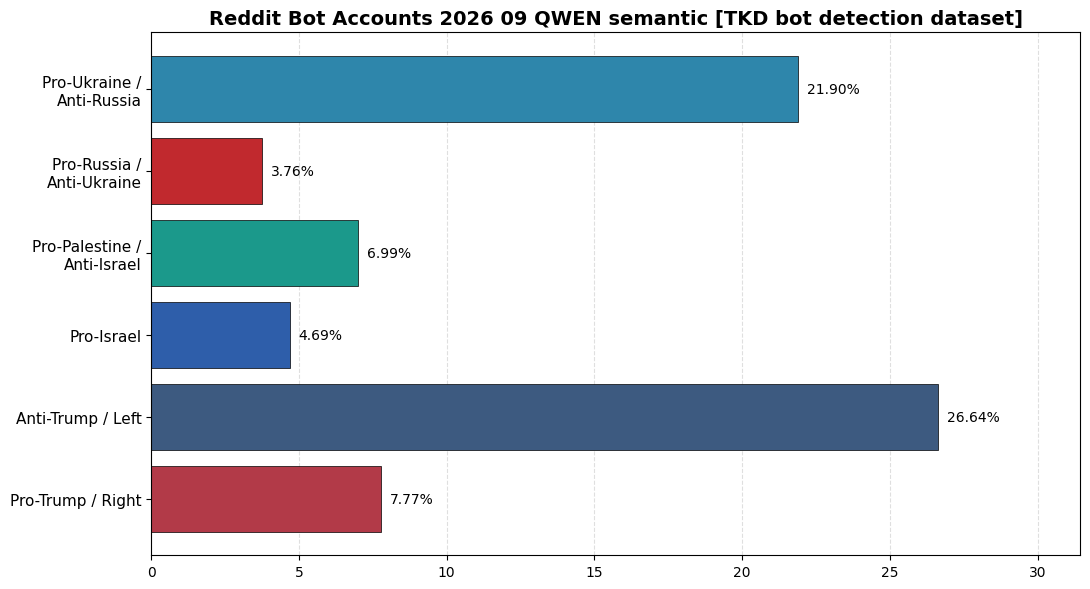

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

labels = [
    "Pro-Ukraine /\nAnti-Russia",
    "Pro-Russia /\nAnti-Ukraine",
    "Pro-Palestine /\nAnti-Israel",
    "Pro-Israel",
    "Anti-Trump / Left",
    "Pro-Trump / Right",
]

shares = [
    pro_ukraine_anti_russia, pro_russia_anti_ukraine, pro_palestine_anti_israel, pro_israel, anti_trump, pro_trump
]
colors = ["#2E86AB", "#C1292E", "#1B998B", "#2E5EAA", "#3D5A80", "#B23A48"]

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(labels))
bars = ax.barh(y, [s * 100 for s in shares], color=colors,
               edgecolor="black", linewidth=0.5)

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=11)
ax.invert_yaxis()

for bar, s in zip(bars, shares):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f"{s*100:.2f}%", va="center", fontsize=10)

ax.set_title("Reddit Bot Accounts 2026 09 QWEN semantic [TKD bot detection dataset]",
             fontsize=14, fontweight="bold")
ax.set_xlim(0, max(s*100 for s in shares) * 1.18)
ax.grid(axis="x", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("shares.png", dpi=150, bbox_inches="tight")
plt.show()